<a href="https://colab.research.google.com/github/dandaocta1/Visualisasi-Data/blob/main/DataVisualization_2418008.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **VISUALISASI DATA KARYAWAN**



## **1. Import Libraries**

In [14]:
import pandas as pd  # Library untuk pengolahan dan analisis data berbentuk tabel
import numpy as np  # Library untuk operasi komputasi numerik
import matplotlib.pyplot as plt  # Modul utama untuk pembuatan visualisasi grafik
import seaborn as sns  # Library visualisasi statistik berbasis matplotlib

## **2. Load DataSet Karyawan**

In [13]:
# Membaca file Excel yang diunggah langsung di penyimpanan Colab
dataset = pd.read_excel('/content/drive/MyDrive/2418008_DataVisualization/DataSet/Data Karyawan.xlsx')

print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)  # Menampilkan total baris dan kolom
print('Lima data teratas:')
print(dataset.head())  # Menampilkan 5 baris pertama data

Ukuran dataset: 100 baris dan 10 kolom

Lima data teratas:
  ID KARYAWAN             NAMA DEPARTEMEN  USIA      GAJI  RATING KERJA  \
0        E001     Budi Santoso         IT    28  10000000          Baik   
1        E002  Revanka Antonio        HRD    25   7000000    Cukup Baik   
2        E003     Rehan Andika         IT    21  10000000        Kurang   
3        E004     Rizki Candra    Finance    27   6000000          Baik   
4        E005    Hun Mie Sheng        HRD    27   7000000  Sangat Buruk   

      USIA.1  GAJI.1      KOTA  KONTRAK  
0  Produktif  Tinggi  Surabaya  1 Tahun  
1       Muda  Sedang   Bandung  2 Tahun  
2       Muda  Tinggi    Malang  2 Tahun  
3  Produktif  Sedang  Surabaya  2 Tahun  
4  Produktif  Sedang   Jakarta  3 Tahun  


## **3. Eksplorasi Informasi Dataset**

In [15]:
print('Informasi Struktur dan Tipe Data:')
dataset.info()  # Menampilkan tipe data serta jumlah data yang terisi

print('\nRingkasan Statistik Data Numerik:')
print(dataset.describe())  # Menampilkan nilai rata-rata, min, max, dan kuartil

Informasi Struktur dan Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ID KARYAWAN   100 non-null    object
 1   NAMA          100 non-null    object
 2   DEPARTEMEN    100 non-null    object
 3   USIA          100 non-null    int64 
 4   GAJI          100 non-null    int64 
 5   RATING KERJA  100 non-null    object
 6   USIA.1        100 non-null    object
 7   GAJI.1        100 non-null    object
 8   KOTA          100 non-null    object
 9   KONTRAK       100 non-null    object
dtypes: int64(2), object(8)
memory usage: 7.9+ KB

Ringkasan Statistik Data Numerik:
             USIA          GAJI
count  100.000000  1.000000e+02
mean    31.780000  7.660000e+06
std      8.470484  1.485417e+06
min     19.000000  6.000000e+06
25%     25.000000  6.000000e+06
50%     29.000000  7.000000e+06
75%     37.000000  8.000000e+06
max     53.000000

## **4. Agregasi Data per Departemen**

In [16]:
# Mengelompokkan data berdasarkan DEPARTEMEN dan menghitung total serta rata-rata GAJI
gaji_dept = dataset.groupby('DEPARTEMEN')['GAJI'].agg(['sum', 'mean', 'count']).reset_index()
gaji_dept.columns = ['DEPARTEMEN', 'TOTAL_GAJI', 'RATA_GAJI', 'JUMLAH_KARYAWAN']

print('Tabel Agregasi per Departemen:')
print(gaji_dept)

Tabel Agregasi per Departemen:
  DEPARTEMEN  TOTAL_GAJI   RATA_GAJI  JUMLAH_KARYAWAN
0    Finance   174000000   6000000.0               29
1        HRD   154000000   7000000.0               22
2         IT   230000000  10000000.0               23
3  Marketing   208000000   8000000.0               26


## **5. Visualisasi 1 - Total Pengeluaran Gaji per Departemen**

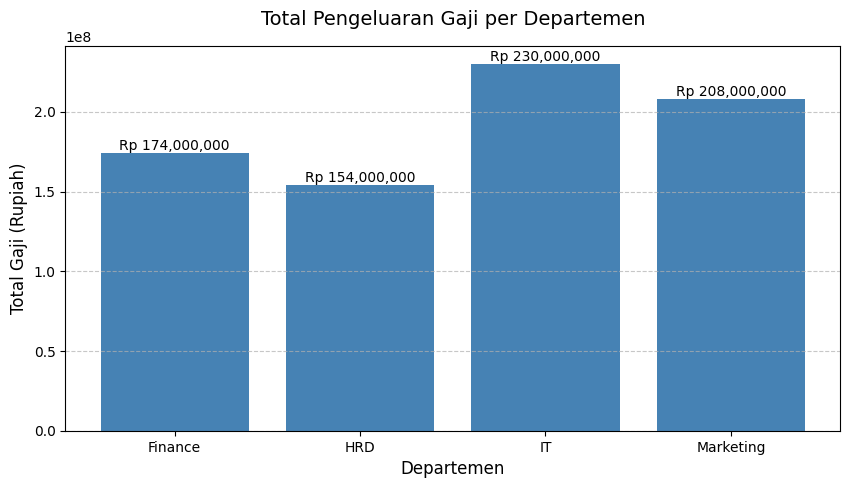

In [17]:
plt.figure(figsize=(10, 5))  # Menentukan ukuran kanvas

# Membuat bar chart total gaji per departemen
bars = plt.bar(gaji_dept['DEPARTEMEN'], gaji_dept['TOTAL_GAJI'], color='steelblue')

plt.title('Total Pengeluaran Gaji per Departemen', fontsize=14, pad=15)  # Judul grafik
plt.xlabel('Departemen', fontsize=12)  # Label sumbu X
plt.ylabel('Total Gaji (Rupiah)', fontsize=12)  # Label sumbu Y
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Menambahkan garis kisi-kisi

# Menambahkan label nilai di atas batang grafik
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'Rp {int(yval):,}', ha='center', va='bottom', fontsize=10)

plt.show()

## **6. Visualisasi 2 - Distribusi Rating Kerja Karyawan**

/tmp/ipykernel_1209/3625318104.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


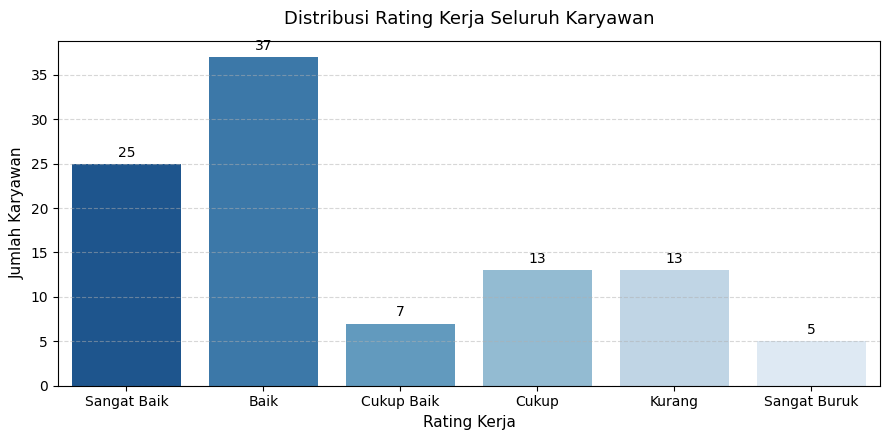

In [23]:
plt.figure(figsize=(9, 4.5))

# Urutan tingkatan rating kerja
rating_order = [
    'Sangat Baik',
    'Baik',
    'Cukup Baik',
    'Cukup',
    'Kurang',
    'Sangat Buruk',
]

# Plot Bar Chart
ax = sns.countplot(
    data=dataset, x='RATING KERJA', order=rating_order, palette='Blues_r'
)

plt.title('Distribusi Rating Kerja Seluruh Karyawan', fontsize=13, pad=12)
plt.xlabel('Rating Kerja', fontsize=11)
plt.ylabel('Jumlah Karyawan', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Menambahkan label angka di atas batang
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10,
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.tight_layout()
plt.show()

## **7. Visualisasi 3 - Grouped Bar Chart Kategori Usia per Departemen**

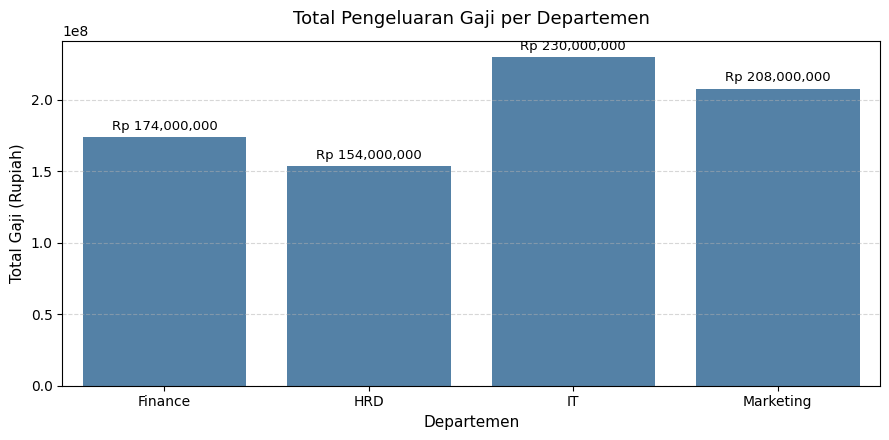

In [21]:
plt.figure(figsize=(9, 4.5))

# Agregasi total gaji per departemen
dept_gaji = dataset.groupby('DEPARTEMEN')['GAJI'].sum().reset_index()

# Plot Bar Chart
ax = sns.barplot(data=dept_gaji, x='DEPARTEMEN', y='GAJI', color='#4682b4')

plt.title('Total Pengeluaran Gaji per Departemen', fontsize=13, pad=12)
plt.xlabel('Departemen', fontsize=11)
plt.ylabel('Total Gaji (Rupiah)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Menambahkan label nominal di atas batang
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'Rp {int(height):,}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9.5,
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.tight_layout()
plt.show()

## **8. Visualisasi 4 - Heatmap Korelasi Pearson ( Usia dan Gaji )**

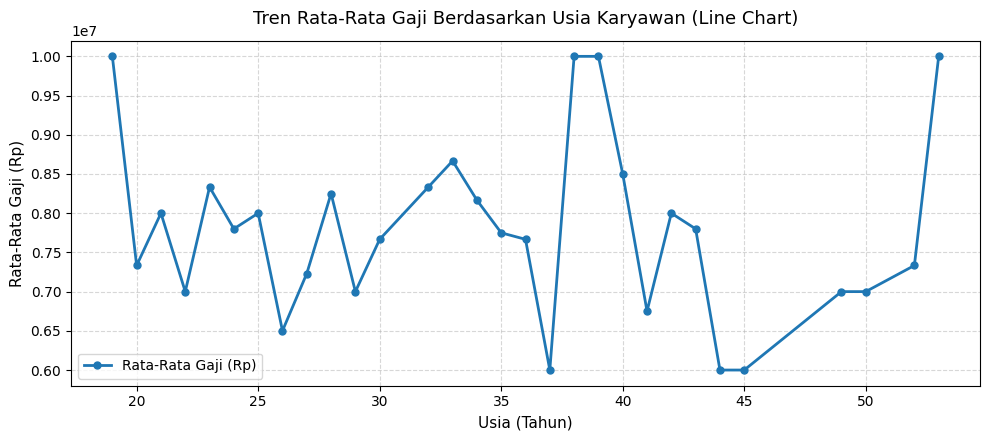

In [22]:
plt.figure(figsize=(10, 4.5))

# Agregasi rata-rata gaji berdasarkan usia
gaji_usia = dataset.groupby('USIA')['GAJI'].mean().reset_index()

# Plot Line Chart (Fluktuasi Naik-Turun)
plt.plot(
    gaji_usia['USIA'],
    gaji_usia['GAJI'],
    marker='o',
    linestyle='-',
    color='#1f77b4',
    linewidth=2,
    markersize=5,
    label='Rata-Rata Gaji (Rp)',
)

plt.title(
    'Tren Rata-Rata Gaji Berdasarkan Usia Karyawan (Line Chart)',
    fontsize=13,
    pad=12,
)
plt.xlabel('Usia (Tahun)', fontsize=11)
plt.ylabel('Rata-Rata Gaji (Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()

## **9. Viusalisai 5 - Distribusi Karyawan Berdasarkan Kota**

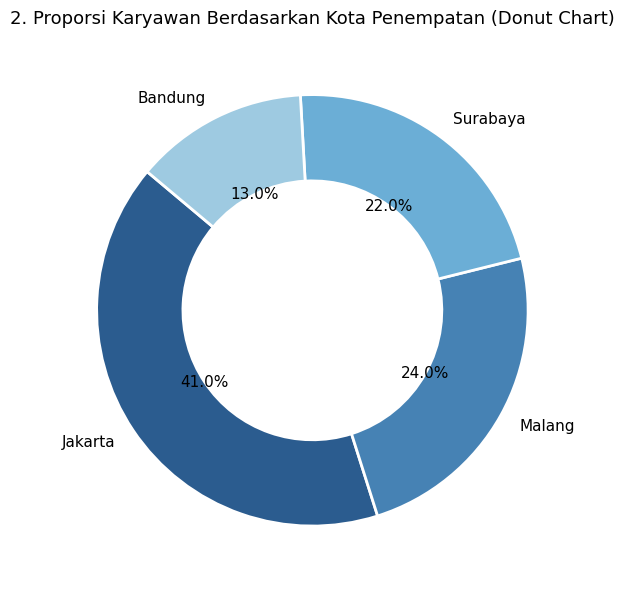

In [26]:
plt.figure(figsize=(6, 6))

# Hitung jumlah karyawan per kota
kota_counts = dataset['KOTA'].value_counts()

# Plot Donut Chart
plt.pie(
    kota_counts,
    labels=kota_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1'],
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11},
)

plt.title(
    '2. Proporsi Karyawan Berdasarkan Kota Penempatan (Donut Chart)',
    fontsize=13,
    pad=12,
)

plt.tight_layout()
plt.show()

# **10. Visualisasi 6 - Distribusi Masa Kontrak Karyawan**

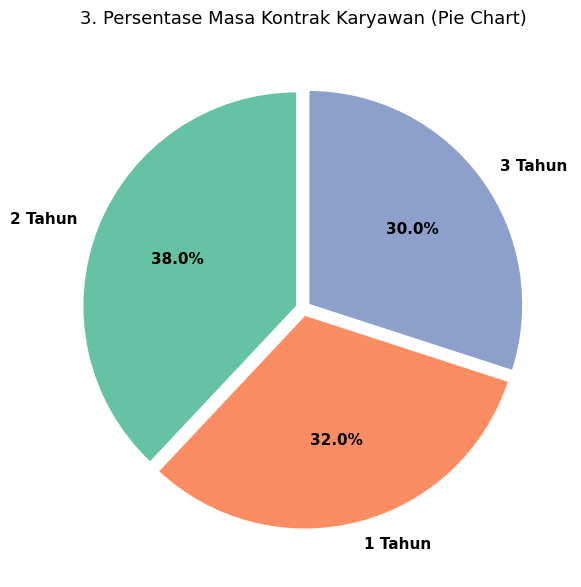

In [28]:
plt.figure(figsize=(6, 6))

# Hitung jumlah karyawan per masa kontrak
kontrak_counts = dataset['KONTRAK'].value_counts()

# Plot Pie Chart
plt.pie(
    kontrak_counts,
    labels=kontrak_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#66c2a5', '#fc8d62', '#8da0cb'],
    explode=(0.03, 0.03, 0.03),
    textprops={'fontsize': 11, 'weight': 'bold'},
    wedgeprops=dict(edgecolor='white', linewidth=1.5),
)

plt.title(
    '3. Persentase Masa Kontrak Karyawan (Pie Chart)', fontsize=13, pad=12
)

plt.tight_layout()
plt.show()